
# CS156 — Session 15: Basis Functions 2 — Ridge and Lasso

**Session Date:** October 29, 2026

**Learning Outcomes:** #optimization and #regression

## Session Objectives

This session explores how regularization changes the optimization process and helps models produce more stable parameter estimates.

I first revisit logistic regression from the Maximum Likelihood Estimation session. I then examine how adding an L2 penalty changes the loss function and its minimum. Finally, I compare parameter estimates across multiple datasets to understand variance.

### Questions I Want to Answer

1. Why do we need regularization?
2. How do Ridge and Lasso modify a loss function?
3. Why does regularization move the minimum of the loss function?
4. How does regularization affect parameter variance?
5. How can I apply these ideas to Yosemite temperature modeling?

The notebook begins with the original PCW. The second part extends the class breakout discussion using Fourier and Gaussian RBF features with Ridge and Lasso regression.



# Part I — Pre-Class Work: Ridge and Lasso

## Question 1 of 8 — Basic Question: Intro

### Question

Why do we need to apply regularization to a model's parameters? What cost function gets minimized when fitting a linear parameter model, and how do Ridge and Lasso modify this function?

### Initial Explanation

A linear regression model typically minimizes the mean squared error (MSE), which measures the average squared difference between actual and predicted values.

$$
\operatorname{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

However, when features are highly correlated or the data is limited, different coefficient combinations may produce similar predictions. This can make parameter estimates unstable.

An ill-posed problem is one where a solution may not exist, may not be unique, or may change dramatically with small changes in the data.

Regularization addresses this by adding a penalty to the loss function.

**Ridge Regression (L2):**

$$
J_{\text{Ridge}}=\operatorname{MSE}+\lambda\sum_{j=1}^{p}\beta_j^2
$$

**Lasso Regression (L1):**

$$
J_{\text{Lasso}}=\operatorname{MSE}+\lambda\sum_{j=1}^{p}|\beta_j|
$$

Ridge encourages smaller coefficients, while Lasso can shrink some coefficients exactly to zero. Both methods can reduce overfitting, although they introduce some bias.

### My Five Whys Discussion

**Why 1: Why does regularization make ill-posed problems more stable?**

Highly correlated features contain similar information, so different parameter combinations can fit the same dataset. Regularization adds a preference for smaller coefficients, helping the model choose a more stable solution.

**Why 2: Why does penalizing large coefficients reduce sensitivity to changes in the data?**

Without regularization, large positive and negative coefficients can cancel each other. Small changes in the data may then produce very different coefficient combinations. Penalizing large values discourages these extreme solutions.

**Why 3: Why does penalizing large coefficients reduce dependence on delicate cancellations?**

Correlated features can exchange their contributions without changing predictions much. Regularization makes extreme combinations expensive, encouraging the model to use smaller coefficients instead.

**Why 4: Why do smaller coefficients help distinguish between equally good solutions?**

Regularization considers both prediction error and coefficient size. For example, if (10, 0) and (5, 5) produce equal prediction errors, Ridge prefers (5, 5) because its squared penalty is 50 rather than 100.

**Why 5: Why can choosing the smallest squared coefficients improve stability?**

My interpretation is that the L2 penalty makes large changes in coefficients more costly. It also adds curvature to the loss function, which can help select a unique solution when the original problem is poorly determined.

### My Interpretation

I learned that regularization does more than reduce coefficient size. It changes the optimization objective, making unstable parameter combinations less attractive. This can reduce variance, although a smaller coefficient does not automatically guarantee better predictions.



## Core Question — Return to Bollywood

### Question

How does L2 regularization change logistic regression parameter estimates, and can it make those estimates more stable across different training datasets?

### My Approach

I revisit the logistic regression model from the Maximum Likelihood Estimation session.

The synthetic dataset uses two known parameters:

- Intercept: $\beta_0=-5$
- Slope: $\beta_1=3$

The model estimates the probability of a binary outcome using the sigmoid function:

$$
P(y=1\mid x)=\frac{1}{1+e^{-(\beta_0+\beta_1x)}}
$$

I will generate 1,000 observations, calculate the negative log-likelihood, visualize the loss surface, and then add regularization.

This allows me to see how the best-fitting parameter values change when the model considers both prediction error and coefficient size.


In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from scipy.special import expit
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import r2_score, mean_absolute_error
import sklearn

# Setting a reproducible random generator
rng = np.random.default_rng(42)

# Generating contour plots over candidate intercepts and slopes
def plot_mesh(fig, ax, fn, x_data, y_data, x_range=(-6, -2), y_range=(0, 4), N=20, cmap="Blues_r", show_true=True):
    beta0_values = np.linspace(*x_range, N)
    beta1_values = np.linspace(*y_range, N)
    mesh_b0, mesh_b1 = np.meshgrid(beta0_values, beta1_values)
    params = {"beta_0": mesh_b0.ravel(), "beta_1": mesh_b1.ravel()}

    # Calculating the loss at every parameter pair
    batched_fn = jax.vmap(fn, in_axes=(0, None, None))
    losses = np.asarray(batched_fn(params, x_data, y_data)).reshape(N, N)

    contour = ax.contourf(mesh_b0, mesh_b1, losses, levels=50, cmap=cmap)
    fig.colorbar(contour, ax=ax)
    ax.set_xlabel("Beta0 (intercept)")
    ax.set_ylabel("Beta1 (slope)")

    # Identifying the minimum inside the plotted region
    best_index = np.argmin(losses)
    best_b0 = mesh_b0.ravel()[best_index]
    best_b1 = mesh_b1.ravel()[best_index]

    ax.scatter(best_b0, best_b1, marker="x", s=65, label="Grid minimum")

    if show_true:
        ax.scatter(-5, 3, marker="x", s=65, label="True value")

    ax.set_title(f"Estimate: beta0={best_b0:.2f}, beta1={best_b1:.2f}")
    ax.legend(fontsize=8)

    return best_b0, best_b1

# Generating binary outcomes using the known parameters
def generate_dataset(n, generator):
    xs = generator.uniform(0, 3, size=n)
    probs = expit(3 * xs - 5)
    ys = (generator.random(n) < probs).astype(np.float32)

    return xs, ys

print("JAX:", jax.__version__)
print("Scikit-learn:", sklearn.__version__)


JAX: 0.11.1
Scikit-learn: 1.6.1



### Code Cell 2 — Generate 1,000 Observations

**Question being answered:** How do we reproduce the dataset used in the maximum-likelihood exercise?

I generate 1,000 observations from the logistic model with true parameters $\beta_0=-5$ and $\beta_1=3$.

The random seed makes the experiment reproducible. However, my estimates may differ from those in the original PCW because the observations are randomly generated.

I also check the proportion of observations labeled 1 to understand the distribution of the binary outcomes.


In [36]:

NUM_DATAPOINTS = 1000

# Generating the synthetic logistic regression dataset
x_data, y_data = generate_dataset(NUM_DATAPOINTS, rng)

# Checking the dataset size and class distribution
print("Number of observations:", len(x_data))
print("Proportion with class 1:", round(float(y_data.mean()), 3))


Number of observations: 1000
Proportion with class 1: 0.423



### Code Cell 3 — Plot Negative Log-Likelihood (NLL)

**Question being answered:** Where is the best-fitting logistic regression parameter pair before regularization?

### Explanation

In the previous maximum-likelihood session, I maximized the log-likelihood to find the best parameter estimates.

Here, I minimize the negative log-likelihood instead. Both methods identify the same parameter values because minimizing the negative of a function is equivalent to maximizing the original function.

For logistic regression:

$$
\operatorname{NLL}(\beta_0,\beta_1)
=-\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

where:

$$
p_i=\frac{1}{1+e^{-(\beta_0+\beta_1x_i)}}
$$

I use the average negative log-likelihood instead of the sum. This changes the numerical scale of the loss but does not change its minimum.

### Expected Plot

The blue contour plot shows the loss for different values of $\beta_0$ and $\beta_1$.

Darker regions represent smaller loss values, while the estimated minimum shows the best-fitting parameter pair within the plotted grid.

I expect this point to be close to the true values of (-5, 3).


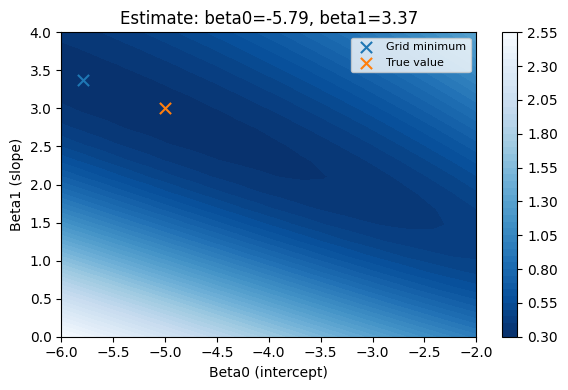

NLL grid minimum: (np.float64(-5.7894736842105265), np.float64(3.3684210526315788))


In [37]:

@jax.jit
def nll(params, xs, ys):
    logits = params["beta_0"] + params["beta_1"] * xs

    # Calculating the average negative log-likelihood
    return jnp.mean(jax.nn.softplus(logits) - ys * logits)

# Visualizing the unregularized loss surface
fig, ax = plt.subplots(figsize=(6, 4))
original_min = plot_mesh(fig, ax, nll, x_data, y_data, cmap="Blues_r")

plt.tight_layout()
plt.show()

print("NLL grid minimum:", original_min)



## Question 2 of 8 — What Does the L2 Norm Plot Show?

### Question

What is shown in the plot? What are the x-axis, y-axis, and colored values?

### Explanation

The L2 norm measures the overall magnitude of a parameter vector. In simple terms, it measures the distance between the parameter values and zero.

For two parameters:

$$
\|\boldsymbol{\beta}\|_2=\sqrt{\beta_0^2+\beta_1^2}
$$

The x-axis represents $\beta_0$ (intercept), while the y-axis represents $\beta_1$ (slope).

The grayscale values represent the L2 norm. Darker regions indicate smaller values, and lighter regions indicate larger values.

### My Interpretation

The plot shows that the penalty becomes larger as the coefficients move farther from zero.

This is useful because regularization discourages unnecessarily large coefficients.

**Important distinction:** This cell calculates the actual L2 norm used in my submitted PCW. Standard Ridge regression generally penalizes the squared L2 norm instead.


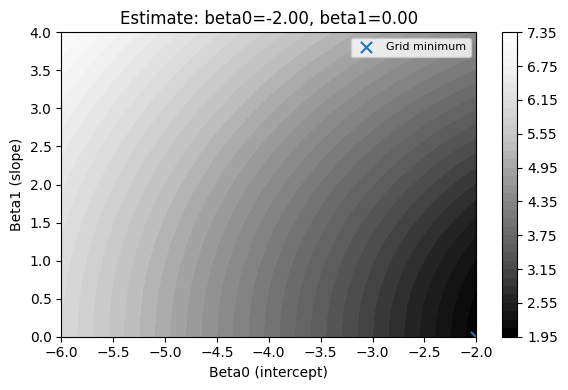

L2 norm grid minimum: (np.float64(-2.0), np.float64(0.0))


In [38]:

@jax.jit
def l2_norm(params, xs, ys):
    beta_0 = params["beta_0"]
    beta_1 = params["beta_1"]

    # Calculating the Euclidean length of the parameter vector
    norm = jnp.sqrt(beta_0**2 + beta_1**2)

    return norm

# Visualizing the L2 norm for different parameter pairs
fig, ax = plt.subplots(figsize=(6, 4))
restricted_l2_min = plot_mesh(fig, ax, l2_norm, x_data, y_data, show_true=False, cmap="Greys_r")

plt.tight_layout()
plt.show()

print("L2 norm grid minimum:", restricted_l2_min)



## Question 3 of 8 — Which Parameter Pair Has the Lowest L2 Norm?

The smallest L2 norm within the plotted range occurs at:

$$
(\beta_0,\beta_1)=(-2,0)
$$

Its L2 norm is:

$$
\sqrt{(-2)^2+0^2}=2
$$

However, this is not the global minimum. Our search is restricted to:

$$
\beta_0\in[-6,-2], \qquad \beta_1\in[0,4]
$$

The global minimum occurs at $(0,0)$, where the L2 norm equals zero.

### My Interpretation

The observed minimum depends on the search boundaries. If the plot included zero for both parameters, we would see the true global minimum.

## Question 4 of 8 — How Do the Scales of NLL and L2 Compare?

The gray L2 plot contains values ranging from approximately 2 to 7.2. The blue NLL plot generally contains smaller values.

If I simply add both losses without scaling, the L2 penalty may dominate the optimization, causing the model to prioritize smaller coefficients over fitting the training data.

To control this tradeoff, I introduce a regularization parameter $\alpha$:

$$
J(\beta)=\operatorname{NLL}(\beta)+\alpha\|\beta\|_2
$$

A small $\alpha$ gives more importance to prediction accuracy, while a larger value increases the penalty for large parameters.

This reproduces the original PCW. Standard Ridge instead uses a squared L2 penalty and normally excludes the intercept.


In [39]:

# Generating the parameter grid
grid_b0 = np.linspace(-6, -2, 20)
grid_b1 = np.linspace(0, 4, 20)
mesh_b0, mesh_b1 = np.meshgrid(grid_b0, grid_b1)

params = {
    "beta_0": mesh_b0.ravel(),
    "beta_1": mesh_b1.ravel()
}

# Calculating both losses on the same grid
nll_grid = np.asarray(jax.vmap(nll, in_axes=(0, None, None))(params, x_data, y_data))
l2_grid = np.asarray(jax.vmap(l2_norm, in_axes=(0, None, None))(params, x_data, y_data))

# Comparing their numerical ranges
print(f"NLL range: {nll_grid.min():.3f} to {nll_grid.max():.3f}")
print(f"L2 norm range: {l2_grid.min():.3f} to {l2_grid.max():.3f}")


NLL range: 0.323 to 2.540
L2 norm range: 2.000 to 7.211



## Question 5 of 8 — How Does Regularization Shift the Minimum?

### Question

Where are the original and modified minima, and why do they shift when regularization is introduced?

### Explanation

I now modify the negative log-likelihood by adding an L2 penalty:

$$
J(\beta_0,\beta_1)=\operatorname{NLL}(\beta_0,\beta_1)+\alpha\sqrt{\beta_0^2+\beta_1^2}
$$

For this experiment:

$$
\alpha=0.01
$$

This is an example of **soft regularization**, as explained by Terence Parr.

Instead of requiring coefficients to remain inside a fixed circle, the optimizer minimizes a new loss function that includes both prediction error and parameter size.

### My Original PCW Results

- Original minimum: $(-4.95,2.95)$
- Modified minimum: $(-4.32,2.53)$

These values came from my earlier run. The code below will produce new values because it uses a new randomly generated dataset.

### My Interpretation

The modified minimum moves toward zero because smaller parameter values now have an advantage.

The model accepts a slightly worse fit to the training data in exchange for smaller coefficients, which may produce more stable estimates.


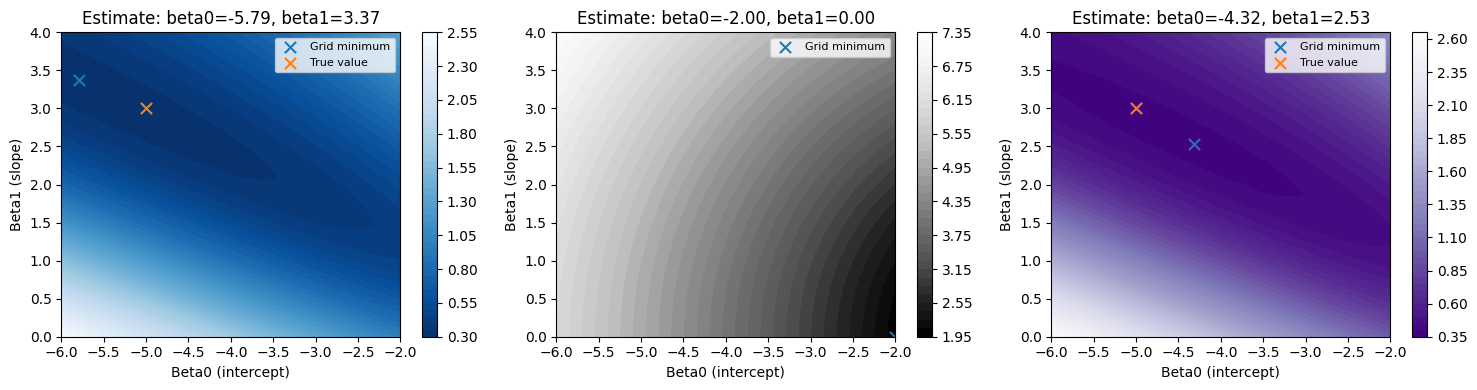

Original grid minimum: (np.float64(-5.7894736842105265), np.float64(3.3684210526315788))
Modified grid minimum: (np.float64(-4.315789473684211), np.float64(2.526315789473684))


In [40]:

@jax.jit
def modified_loss(params, xs, ys, alpha=1e-2):
    # Adding the scaled L2 norm to the negative log-likelihood
    return nll(params, xs, ys) + alpha * l2_norm(params, xs, ys)

# Comparing the original loss, penalty, and modified loss
fig, axes = plt.subplots(ncols=3, figsize=(15, 4))

before_min = plot_mesh(fig, axes[0], nll, x_data, y_data, cmap="Blues_r")
penalty_min = plot_mesh(fig, axes[1], l2_norm, x_data, y_data, show_true=False, cmap="Greys_r")
after_min = plot_mesh(fig, axes[2], modified_loss, x_data, y_data, cmap="Purples_r")

plt.tight_layout()
plt.show()

print("Original grid minimum:", before_min)
print("Modified grid minimum:", after_min)



### Code Cell 7 — Resample Five Datasets and Record the Minima

**Question being answered:** Does the minimum of the original or modified loss function move around more when the training data changes?

### My Approach

I generate five new datasets, each containing 1,000 observations.

For each dataset, I calculate:

1. The minimum of the original negative log-likelihood.
2. The minimum after adding the L2 penalty.

I then compare how much the estimated parameter values change between datasets.

This is useful because parameter stability cannot be judged from only one training sample.


In [41]:

five_runs = []

# Repeating the estimation with five new datasets
for run in range(1, 6):
    sampled_x, sampled_y = generate_dataset(NUM_DATAPOINTS, rng)

    # Calculating both loss surfaces
    original_values = np.asarray(jax.vmap(nll, in_axes=(0, None, None))(params, sampled_x, sampled_y))
    modified_values = np.asarray(jax.vmap(modified_loss, in_axes=(0, None, None))(params, sampled_x, sampled_y))

    # Locating each minimum
    old_idx = int(np.argmin(original_values))
    new_idx = int(np.argmin(modified_values))

    # Storing the parameter estimates
    five_runs.append({
        "Run": run,
        "Original beta0": params["beta_0"][old_idx],
        "Original beta1": params["beta_1"][old_idx],
        "Modified beta0": params["beta_0"][new_idx],
        "Modified beta1": params["beta_1"][new_idx]
    })

five_results = pd.DataFrame(five_runs)
display(five_results.round(3))


,Run,Original beta0,Original beta1,Modified beta0,Modified beta1
0,1,-5.158,3.158,-4.105,2.526
1,2,-5.158,3.158,-4.105,2.526
2,3,-4.737,2.737,-3.895,2.316
3,4,-4.947,2.947,-4.105,2.526
4,5,-4.947,2.947,-3.895,2.316



### Interpretation — Why Might the Modified Minimum Move Less?

Regularization discourages large coefficients, which can make parameter estimates less sensitive to changes in the training data.

This is part of the **bias–variance tradeoff**. Regularization may introduce some bias, but it can reduce the variance of estimated parameters.

My original PCW suggested that the modified minima moved less than the unregularized minima.

However, regularization does not guarantee that every parameter will have lower variance in every experiment. I therefore need more samples to measure this effect reliably.

### Distinguishing the L2 Norm from Standard Ridge

The previous exercise used:

$$
\operatorname{NLL}+\alpha\sqrt{\beta_0^2+\beta_1^2}
$$

Standard Ridge regularization instead uses a squared L2 penalty, usually excluding the intercept:

$$
\operatorname{NLL}+\alpha\beta_1^2
$$

I will compare these two loss functions to understand the mathematical difference.


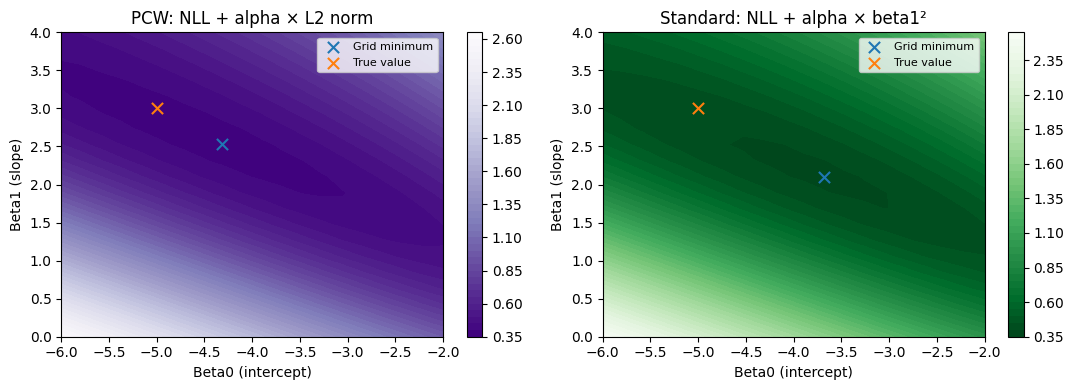

In [42]:

@jax.jit
def standard_ridge_loss(params, xs, ys, alpha=1e-2):
    # Penalizing the squared slope, without penalizing the intercept
    return nll(params, xs, ys) + alpha * params["beta_1"]**2

# Comparing the two regularized loss surfaces
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

plot_mesh(fig, axes[0], modified_loss, x_data, y_data, cmap="Purples_r")
plot_mesh(fig, axes[1], standard_ridge_loss, x_data, y_data, cmap="Greens_r")

axes[0].set_title("PCW: NLL + alpha × L2 norm")
axes[1].set_title("Standard: NLL + alpha × beta1²")

plt.tight_layout()
plt.show()



## Extension 4 — Thinking in Distributions

### Question

Across 50 randomly generated datasets, how much do the estimated model parameters vary?

### My Approach

For each dataset, I fit two models:

1. Logistic Regression without regularization.
2. RidgeClassifier with $\alpha=0.01$.

I extract the intercept $\beta_0$ using `.intercept_` and the slope $\beta_1$ using `.coef_`.

After 50 runs, I create scatterplots of the estimated parameter pairs and calculate the variance of each parameter.

### Mathematical Explanation

The sample variance measures how much the estimates change around their average value:

$$
s^2=\frac{1}{n-1}\sum_{i=1}^{n}(\beta_i-\bar{\beta})^2
$$

A larger variance means the parameter estimates are less stable across datasets.

**Important limitation:** RidgeClassifier uses a different loss function from logistic regression, so the comparison does not isolate the effect of regularization alone.


In [43]:

# Handling older and newer scikit-learn penalty options
def logistic_without_penalty():
    version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])

    if version >= (1, 8):
        return LogisticRegression(C=np.inf, max_iter=2000)

    if version >= (1, 2):
        return LogisticRegression(penalty=None, max_iter=2000)

    return LogisticRegression(penalty="none", max_iter=2000)

logistic_params = []
ridge_params = []

# Resampling 50 independent datasets
for run in range(50):
    sampled_x, sampled_y = generate_dataset(NUM_DATAPOINTS, rng)
    X = sampled_x.reshape(-1, 1)

    # Fitting both models on the same dataset
    logistic = logistic_without_penalty()
    ridge = RidgeClassifier(alpha=1e-2)

    logistic.fit(X, sampled_y)
    ridge.fit(X, sampled_y)

    # Storing the intercept and slope
    logistic_params.append([float(np.ravel(logistic.intercept_)[0]), float(np.ravel(logistic.coef_)[0])])
    ridge_params.append([float(np.ravel(ridge.intercept_)[0]), float(np.ravel(ridge.coef_)[0])])

logistic_params = np.asarray(logistic_params)
ridge_params = np.asarray(ridge_params)

print("Datasets used:", len(logistic_params))


Datasets used: 50



### Code Cell 10 — Plot the Estimates and Calculate Variance

**Question being answered:** Which model has more variable parameter estimates?

Each scatterplot shows the intercept and slope estimated from 50 datasets.

The horizontal axis represents $\beta_0$, while the vertical axis represents $\beta_1$.

If the points are widely spread, the coefficients change considerably between datasets. If the points are closer together, the estimates are more consistent.

I calculate the variance of each coefficient separately, using sample variance with `ddof=1`.


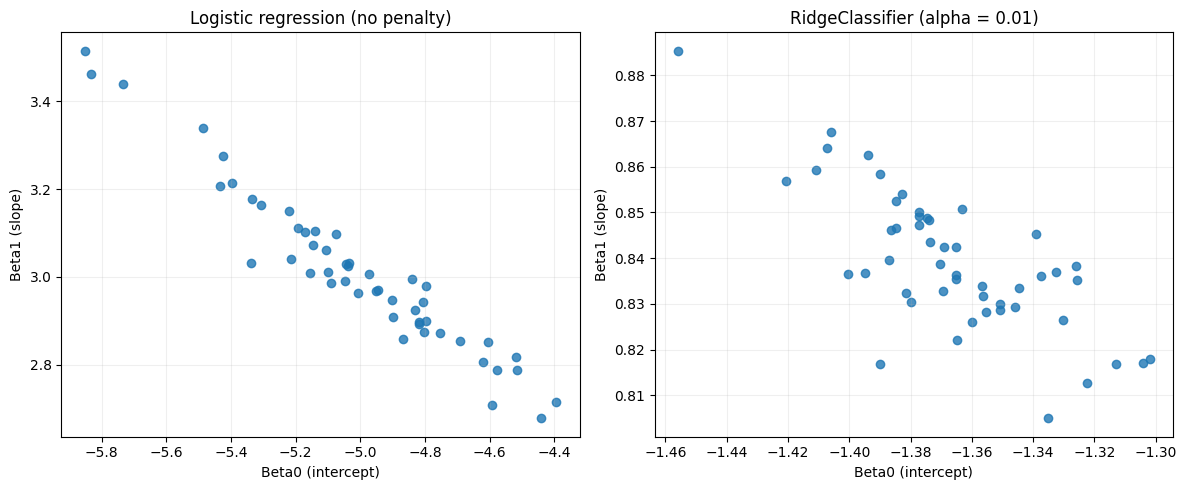

,Parameter,Logistic (no penalty),RidgeClassifier
0,Beta0,0.113464,0.000931
1,Beta1,0.034029,0.000236


In [44]:

# Plotting the estimated parameter pairs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(logistic_params[:, 0], logistic_params[:, 1], alpha=0.8)
axes[0].set_title("Logistic regression (no penalty)")

axes[1].scatter(ridge_params[:, 0], ridge_params[:, 1], alpha=0.8)
axes[1].set_title("RidgeClassifier (alpha = 0.01)")

for ax in axes:
    ax.set_xlabel("Beta0 (intercept)")
    ax.set_ylabel("Beta1 (slope)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Calculating sample variance for both parameters
variance_table = pd.DataFrame({
    "Parameter": ["Beta0", "Beta1"],
    "Logistic (no penalty)": np.var(logistic_params, axis=0, ddof=1),
    "RidgeClassifier": np.var(ridge_params, axis=0, ddof=1)
})

display(variance_table.round(6))



## Question 6 of 8 — Which Model Produced Higher Coefficient Variance?

### My Original PCW Results

| Parameter | Logistic Regression | RidgeClassifier |
|---|---:|---:|
| Variance of $\beta_0$ | 0.1172 | 0.000934 |
| Variance of $\beta_1$ | 0.0408 | 0.000347 |

These values came from my earlier 50-dataset experiment. The newly generated experiment may produce slightly different numbers.

### My Interpretation

The unregularized logistic regression model had higher coefficient variance. Its parameter estimates were more spread out across datasets, while the RidgeClassifier estimates were more closely grouped.

However, the two methods use different loss functions and parameter scales, so I cannot attribute the entire difference to regularization.

## Question 7 of 8 — How Does the Bias–Variance Tradeoff Work Here?

Regularization penalizes large coefficients, making the model less sensitive to changes in the training data.

This can introduce more bias because the fitted coefficients may move away from the values that minimize the original training loss.

In exchange, the model may have lower variance, meaning its estimates change less across training datasets.

The goal is to improve generalization to unseen data rather than simply minimize training error.

### A More Controlled Comparison

To better isolate regularization, I will compare logistic regression with and without L2 regularization, keeping the same model family and the same datasets.

In scikit-learn, `C` represents the inverse of regularization strength. Smaller values of `C` produce stronger regularization.


In [45]:

unregularized_params = []
l2_logistic_params = []

# Comparing the same model family on the same datasets
for run in range(50):
    sampled_x, sampled_y = generate_dataset(NUM_DATAPOINTS, rng)
    X = sampled_x.reshape(-1, 1)

    plain = logistic_without_penalty()
    regularized = LogisticRegression(C=1.0, max_iter=2000)

    # Training both models
    plain.fit(X, sampled_y)
    regularized.fit(X, sampled_y)

    # Recording their fitted parameters
    unregularized_params.append([float(plain.intercept_[0]), float(plain.coef_[0, 0])])
    l2_logistic_params.append([float(regularized.intercept_[0]), float(regularized.coef_[0, 0])])

unregularized_params = np.asarray(unregularized_params)
l2_logistic_params = np.asarray(l2_logistic_params)

# Comparing the coefficient variances
fair_table = pd.DataFrame({
    "Parameter": ["Beta0", "Beta1"],
    "No penalty": np.var(unregularized_params, axis=0, ddof=1),
    "L2 logistic (C=1)": np.var(l2_logistic_params, axis=0, ddof=1)
})

display(fair_table.round(6))


,Parameter,No penalty,L2 logistic (C=1)
0,Beta0,0.087355,0.071333
1,Beta1,0.031190,0.025352



## Question 8 of 8 — Submission

The original question was an upload slot, so it does not require another model or calculation.

## PCW Conclusion

This exercise helped me understand regularization at both a mathematical and practical level.

I learned that adding a penalty changes the loss function itself, which shifts the minimum toward smaller coefficient values. This is different from simply imposing a strict boundary on the parameters.

The repeated sampling experiments also helped me understand parameter variance. Rather than assuming that regularization improves stability, I can measure how much the estimated coefficients change across datasets.

### Main Takeaway

Regularization introduces a tradeoff between fitting the training data and controlling coefficient size. Ridge uses a squared L2 penalty, while Lasso uses an L1 penalty that can set coefficients exactly to zero.

These ideas provide the basis for the Yosemite temperature modeling extension, where I will introduce nonlinear features and compare Ridge and Lasso.



# Part II — Yosemite Temperature Modeling Extension

## Main Research Question

Can Fourier features, Gaussian RBFs, and regularization improve the R² score of our Yosemite temperature prediction model?

### Background

During the class breakout, we discussed how nonlinear features might improve temperature predictions.

A simple linear regression model cannot easily capture the daily and seasonal changes in temperature. For example, Yosemite temperatures are generally warmer during summer and cooler during winter; they also change throughout each day.

Another student reported an R² of approximately 0.62 using Gaussian RBF features with Ridge regression. This provides a useful reference, although we cannot compare the scores directly without using the same training and testing data.

### My Proposed Improvements

I will compare:

1. Linear Regression as a baseline.
2. Gaussian RBF + Ridge Regression.
3. Gaussian RBF + Lasso Regression.
4. Fourier Features + Ridge Regression.
5. Fourier Features + Lasso Regression.
6. Combined Fourier and Gaussian RBF features with Ridge or Lasso.

### Why These Techniques?

Gaussian RBFs can capture smooth nonlinear relationships by measuring how close an observation is to different feature centers.

Fourier features use sine and cosine functions to represent repeating patterns, such as daily and seasonal temperature cycles.

Ridge regularization reduces overfitting by shrinking coefficients, while Lasso may set less useful coefficients to zero.

### Evaluation

I will evaluate the models using R² and mean absolute error (MAE).

My goal is not simply to improve the training score. I want to identify a model that performs better on observations it did not see during training.



## Yosemite Question A — How Should We Represent Time?

### Question

How can I prepare Yosemite temperature data so that the model can learn daily and seasonal patterns?

### My Approach

I begin by loading the Yosemite dataset from the GitHub Gist provided during class.

The dataset contains temperature observations collected over time. I first inspect its columns and check how the timestamps and temperature values are stored.

This step is necessary because later models require two pieces of information:

- When each temperature measurement was recorded.
- The corresponding observed temperature.

I will use timestamps to construct new features, rather than treating all observations as unrelated records.

### Why This Matters

Time has a repeating structure. Midnight is close to the following midnight, and the end of December is close to the beginning of January.

Representing these cycles correctly may help the model capture patterns that ordinary linear regression misses.


In [46]:

import io
import re

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor

# Loading the Yosemite dataset from the raw GitHub Gist
YOSEMITE_URL = "https://gist.githubusercontent.com/Prof-Watson/dedfbf237d013900fa5c4b54c5fd939a/raw"

try:
    data = pd.read_csv(YOSEMITE_URL)
    print("Loaded Yosemite data from the raw Gist URL.")

except Exception as exc:
    print("Automatic download failed:", str(exc)[:200])
    print("Upload the CSV file when prompted.")

    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    data = pd.read_csv(io.BytesIO(uploaded[filename]))

# Inspecting the dataset structure
print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())

display(data.head())


Loaded Yosemite data from the raw Gist URL.
Dataset shape: (105407, 1)
Columns: ['53150 20120101 0005 20111231 1605      2 -119.82   37.76    10.6     0.0 -99999 0 -9999.0 U 0    18 0 -99.000 -9999.0  1223 0 -99.00 0']


,53150 20120101 0005 20111231 1605 2 -119.82 37.76 10.6 0.0 -99999 0 -9999.0 U 0 18 0 -99.000 -9999.0 1223 0 -99.00 0
0,53150 20120101 0010 20111231 1610 2 -119....
1,53150 20120101 0015 20111231 1615 2 -119....
2,53150 20120101 0020 20111231 1620 2 -119....
3,53150 20120101 0025 20111231 1625 2 -119....
4,53150 20120101 0030 20111231 1630 2 -119....



## Yosemite Question B — Which Columns Contain Time and Temperature?

### Question

How can I identify the columns needed for temperature prediction and prepare them for modeling?

### My Approach

I identify the timestamp and temperature columns, convert them into the appropriate formats, and remove missing observations.

The timestamps are converted into datetime values, while temperature measurements are converted into numerical values.

I also sort the observations chronologically and remove duplicate timestamps.

### Why I Am Doing This

The feature-generation functions need valid timestamps to calculate time of day and position within the year.

Sorting and cleaning the dataset also makes the later visualizations easier to interpret.

I focus on the year 2016 when those observations are available, matching the year shown in our class example.

### Interpretation

After cleaning, I inspect the number of observations, date range, and temperature range to make sure the dataset is suitable for modeling.

If the automatic column detection is incorrect, I will manually specify the correct column names.


In [34]:
# Leaving these as None enables automatic column detection
TIME_COLUMN = None
TEMP_COLUMN = None
YEAR_TO_USE = 2016

# If the dataframe was incorrectly read as a single column due to whitespace delimiter, repair it here
if len(data.columns) == 1 and " " in data.columns[0]:
    import io
    raw_text = "\n".join([data.columns[0]] + data.iloc[:, 0].astype(str).tolist())
    # Reading without headers because the dataset has no header row
    data = pd.read_csv(io.StringIO(raw_text), sep="\\s+", header=None)
elif not isinstance(data.columns[0], int) and data.columns[0] == '53150':
    # If it was already split but treated the first row as header
    import io
    # Re-read raw_text if it is still available, or reconstruct from columns + data
    raw_line = " ".join(data.columns.astype(str))
    raw_text = "\n".join([raw_line] + data.astype(str).agg(' '.join, axis=1).tolist())
    data = pd.read_csv(io.StringIO(raw_text), sep="\\s+", header=None)

# Since there are no headers, we will map them directly by their numeric indices:
# Column 1: Date (e.g. 20120101)
# Column 2: Time (e.g. 0005)
# Column 8: Temperature (e.g. 10.6)
if 1 in data.columns and 8 in data.columns:
    # Construct a timestamp from Date (Col 1) and Time (Col 2)
    date_series = data[1].astype(str)
    time_series = data[2].astype(str).str.zfill(4)
    time_values = pd.to_datetime(date_series + " " + time_series, format="%Y%m%d %H%M", errors="coerce")
    parsed_temp = pd.to_numeric(data[8], errors="coerce")
else:
    # Fallback to general lookup if structure changed
    TIME_COLUMN = data.columns[1]
    TEMP_COLUMN = data.columns[8]
    time_values = data[TIME_COLUMN]
    parsed_temp = pd.to_numeric(data[TEMP_COLUMN], errors="coerce")

# Converting timestamps and temperatures into usable values
parsed_time = pd.to_datetime(time_values, errors="coerce")

yosemite = pd.DataFrame({
    "timestamp": parsed_time,
    "temperature": parsed_temp
}).dropna()

# Sorting and removing duplicate timestamps
yosemite = yosemite.sort_values("timestamp").drop_duplicates("timestamp").reset_index(drop=True)

# Selecting 2016 when available
year_rows = yosemite["timestamp"].dt.year == YEAR_TO_USE

if year_rows.any():
    yosemite = yosemite.loc[year_rows].copy()
else:
    print(f"No {YEAR_TO_USE} observations found; retaining available dates.")

# Checking that enough observations remain
if len(yosemite) < 100:
    raise ValueError("Too few valid rows. Check the timestamp and temperature columns.")

print("Usable rows:", len(yosemite))
print("Date range:", yosemite["timestamp"].min(), "to", yosemite["timestamp"].max())
print("Temperature range:", yosemite["temperature"].min(), "to", yosemite["temperature"].max())

display(yosemite.head())

No 2016 observations found; retaining available dates.
Usable rows: 105408
Date range: 2012-01-01 00:05:00 to 2013-01-01 00:00:00
Temperature range: -9999.0 to 29.9


,timestamp,temperature
0,2012-01-01 00:05:00,10.6
1,2012-01-01 00:10:00,10.5
2,2012-01-01 00:15:00,10.1
3,2012-01-01 00:20:00,9.7
4,2012-01-01 00:25:00,9.7



## Yosemite Question C — How Can We Evaluate the Model Without Data Leakage?

### Question

How should I divide Yosemite temperature observations into training, validation, and testing datasets?

### Explanation

The original Yosemite measurements were collected approximately every five minutes. Therefore, observations recorded close together are likely to have similar temperatures.

If I randomly split individual rows, nearby measurements could appear in both training and testing. This may produce overly optimistic results.

### My Approach

I divide the data using complete calendar weeks rather than individual observations.

I create three datasets:

**Training Data:** Used to fit model parameters.

**Validation Data:** Used to compare models and choose regularization strengths.

**Test Data:** Used for the final evaluation after model selection.

### Why This Is Important

A model should be evaluated using observations it has not seen during training.

Separating complete weeks reduces the chance that very similar neighboring measurements appear in different datasets.

This experiment tests predictions on held-out weeks within the same year. It does not establish how well the model would forecast a completely new year.


In [47]:

# Creating weekly groups for the temperature observations
week_groups = yosemite["timestamp"].dt.to_period("W").astype(str).to_numpy()
all_indices = np.arange(len(yosemite))

# Separating development and final test weeks
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
development_idx, test_idx = next(outer_split.split(all_indices, groups=week_groups))

# Separating training and validation weeks
inner_split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=21)
train_local, val_local = next(inner_split.split(development_idx, groups=week_groups[development_idx]))

train_idx = development_idx[train_local]
val_idx = development_idx[val_local]

# Retrieving timestamps for selected observations
def get_time(indices):
    return pd.DatetimeIndex(yosemite.iloc[indices]["timestamp"])

# Retrieving temperatures for selected observations
def get_target(indices):
    return yosemite.iloc[indices]["temperature"].to_numpy(dtype=float)

train_times = get_time(train_idx)
val_times = get_time(val_idx)
test_times = get_time(test_idx)

y_train = get_target(train_idx)
y_val = get_target(val_idx)
y_test = get_target(test_idx)

# Checking dataset sizes
print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Testing rows:", len(test_idx))

print("Training weeks:", len(np.unique(week_groups[train_idx])))
print("Validation weeks:", len(np.unique(week_groups[val_idx])))
print("Testing weeks:", len(np.unique(week_groups[test_idx])))

# Checking that no week appears in multiple sets
assert not set(week_groups[train_idx]) & set(week_groups[val_idx])
assert not set(week_groups[train_idx]) & set(week_groups[test_idx])
assert not set(week_groups[val_idx]) & set(week_groups[test_idx])


Training rows: 65088
Validation rows: 18144
Testing rows: 22176
Training weeks: 34
Validation weeks: 9
Testing weeks: 11



## Yosemite Question D — Can Fourier and Gaussian RBF Features Capture Nonlinear Temperature Patterns?

### Question

How can I transform time into features that represent daily and seasonal temperature changes?

### Fourier Features

Fourier features use sine and cosine functions to represent repeating patterns.

For a time value $t$ and frequency $k$:

$$
\phi_{\sin}(t)=\sin(2\pi kt)
$$

$$
\phi_{\cos}(t)=\cos(2\pi kt)
$$

For this experiment, I apply these functions to two time measurements:

- Fraction of the day.
- Fraction of the year.

The resulting features capture daily and seasonal cycles.

I also include interactions between daily and annual features. This allows the model to represent different daily temperature patterns across seasons.

### Gaussian Radial Basis Functions

Gaussian RBFs measure how close an observation is to a center.

$$
\phi_j(x)=\exp\left(-\frac{\|x-c_j\|^2}{2\sigma^2}\right)
$$

Here:

- $x$ is the input.
- $c_j$ is the center of a basis function.
- $\sigma$ controls how widely the function responds around its center.

I use periodic distances so that times near midnight or the beginning and end of the year remain close to each other.

### Why Compare Both Techniques?

Fourier features capture repeating patterns using waves, while Gaussian RBFs represent smooth local relationships.

Both methods can produce nonlinear predictions while still allowing a linear regression model to learn the coefficients.

However, generating many features increases model flexibility and may increase overfitting.

I will therefore combine these features with Ridge and Lasso regularization.


In [48]:

# Converting timestamps into fractions of a day and year
def time_cycles(timestamps):
    dates = pd.DatetimeIndex(timestamps)

    day_fraction = (dates.hour + dates.minute / 60 + dates.second / 3600) / 24

    days_in_year = np.where(dates.is_leap_year, 366, 365)
    year_fraction = (dates.dayofyear - 1 + day_fraction) / days_in_year

    return np.asarray(day_fraction), np.asarray(year_fraction)

# Generating repeating sine and cosine features
def fourier_features(timestamps, harmonics=3):
    daily, yearly = time_cycles(timestamps)
    features = []

    for k in range(1, harmonics + 1):
        features.extend([np.sin(2 * np.pi * k * daily), np.cos(2 * np.pi * k * daily)])
        features.extend([np.sin(2 * np.pi * k * yearly), np.cos(2 * np.pi * k * yearly)])

    # Adding interactions between daily and seasonal patterns
    for daily_fn in [np.sin(2 * np.pi * daily), np.cos(2 * np.pi * daily)]:
        for year_fn in [np.sin(2 * np.pi * yearly), np.cos(2 * np.pi * yearly)]:
            features.append(daily_fn * year_fn)

    return np.column_stack(features)

# Generating Gaussian RBF features using cyclic distances
def gaussian_rbf_features(timestamps, season_centers=8, hour_centers=6, season_width=0.20, hour_width=0.22):
    daily, yearly = time_cycles(timestamps)

    daily_centers = np.arange(hour_centers) / hour_centers
    yearly_centers = np.arange(season_centers) / season_centers

    features = []

    for year_center in yearly_centers:
        year_gap = np.abs(yearly - year_center)
        year_gap = np.minimum(year_gap, 1 - year_gap)

        for hour_center in daily_centers:
            hour_gap = np.abs(daily - hour_center)
            hour_gap = np.minimum(hour_gap, 1 - hour_gap)

            # Calculating the Gaussian response around each center
            features.append(np.exp(-0.5 * ((year_gap / season_width)**2 + (hour_gap / hour_width)**2)))

    return np.column_stack(features)

# Selecting the requested feature representation
def make_features(timestamps, kind):
    if kind == "linear":
        daily, yearly = time_cycles(timestamps)
        return np.column_stack([daily, yearly])

    if kind == "fourier":
        return fourier_features(timestamps)

    if kind == "rbf":
        return gaussian_rbf_features(timestamps)

    if kind == "hybrid":
        return np.column_stack([fourier_features(timestamps), gaussian_rbf_features(timestamps)])

    raise ValueError(f"Unknown feature family: {kind}")

# Inspecting how many features each method creates
for name in ["linear", "fourier", "rbf", "hybrid"]:
    print(f"{name}: {make_features(train_times[:10], name).shape[1]} features")


linear: 2 features
fourier: 16 features
rbf: 48 features
hybrid: 64 features



## Yosemite Question E — Does Ridge or Lasso Improve R²?

### Question

Can regularization improve the predictive performance of models built with Fourier and Gaussian RBF features?

### My Approach

I compare models using the same training and validation datasets.

For each nonlinear feature representation, I test two regularization methods:

**Ridge Regression (L2):**

$$
J_{\text{Ridge}}=\operatorname{MSE}+\lambda\sum_{j=1}^{p}\beta_j^2
$$

**Lasso Regression (L1):**

$$
J_{\text{Lasso}}=\operatorname{MSE}+\lambda\sum_{j=1}^{p}|\beta_j|
$$

Ridge shrinks the feature coefficients toward zero, while Lasso can remove less useful features by making their coefficients exactly zero.

### Evaluation Metric: R²

$$
R^2=1-\frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}
$$

R² measures how well the model predicts the observed temperature values relative to a constant-mean baseline.

- $R^2=1$: Perfect predictions.
- $R^2=0$: Equivalent to predicting the evaluation-set mean.
- $R^2<0$: Worse than predicting the evaluation-set mean.

### Hyperparameter Tuning

I test several alpha values for Ridge and Lasso.

For Ridge, I test:

$$
\alpha\in\{0.1,10,1000\}
$$

For Lasso, I test:

$$
\alpha\in\{0.0001,0.001,0.01\}
$$

I select the best settings using validation R², rather than training or final test performance.

I also standardize the features within each model pipeline so their scales do not unfairly influence the regularization penalty.

### My Expectation

Nonlinear features may improve R² compared with the linear baseline. Regularization may also reduce overfitting when many features are introduced.

However, I cannot assume that Lasso or Ridge will perform better before evaluating the models.


In [30]:

# Defining the feature families and regularization strengths
feature_families = ["fourier", "rbf", "hybrid"]

alpha_options = {
    "Ridge": [0.1, 10.0, 1000.0],
    "Lasso": [0.0001, 0.001, 0.01]}

# Preparing the training and validation features
feature_cache = {
    kind: (make_features(train_times, kind), make_features(val_times, kind))
    for kind in feature_families}

records = []

# Evaluating simple baseline models first
base_X_train = make_features(train_times, "linear")
base_X_val = make_features(val_times, "linear")

baseline_models = [
    ("Predict train mean", DummyRegressor(strategy="mean")),
    ("Linear time baseline", LinearRegression())]

for name, model in baseline_models:
    model.fit(base_X_train, y_train)
    val_pred = model.predict(base_X_val)

    records.append({
        "Model": name,
        "Features": "linear",
        "Penalty": "none",
        "Alpha": np.nan,
        "Validation R2": r2_score(y_val, val_pred),
        "Validation MAE": mean_absolute_error(y_val, val_pred)})

# Evaluating Ridge and Lasso for each feature representation
for kind in feature_families:
    X_train, X_val = feature_cache[kind]

    for penalty, alphas in alpha_options.items():
        for alpha in alphas:
            if penalty == "Ridge":
                estimator = Ridge(alpha=alpha)
            else:
                estimator = Lasso(alpha=alpha, max_iter=10000, tol=1e-3)

            # Standardizing features and fitting the model
            model = make_pipeline(StandardScaler(), estimator)
            model.fit(X_train, y_train)

            # Predicting validation temperatures
            pred = model.predict(X_val)

            records.append({
                "Model": f"{kind.title()} + {penalty}",
                "Features": kind,
                "Penalty": penalty,
                "Alpha": alpha,
                "Validation R2": r2_score(y_val, pred),
                "Validation MAE": mean_absolute_error(y_val, pred)})

# Ranking all model and alpha combinations
all_trials = pd.DataFrame(records).sort_values("Validation R2", ascending=False)

# Retaining the strongest alpha for each candidate model
best_by_model = all_trials.drop_duplicates("Model").sort_values("Validation R2", ascending=False).reset_index(drop=True)

display(best_by_model.round(4))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.279e+09, tolerance: 6.711e+06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.034e+09, tolerance: 6.711e+06
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.720e+09, tolerance: 6.711e

,Model,Features,Penalty,Alpha,Validation R2,Validation MAE
0,Predict train mean,linear,none,NaN,-0.0155,11.6470
1,Linear time baseline,linear,none,NaN,-0.0350,13.6951
2,Hybrid + Ridge,hybrid,Ridge,10.000,-0.0499,13.3605
3,Rbf + Ridge,rbf,Ridge,1000.000,-0.0501,12.4866
4,Rbf + Lasso,rbf,Lasso,0.010,-0.0501,11.9815
5,Hybrid + Lasso,hybrid,Lasso,0.001,-0.0527,14.9134
6,Fourier + Ridge,fourier,Ridge,1000.000,-0.0748,17.2754
7,Fourier + Lasso,fourier,Lasso,0.010,-0.0766,17.4701



## Yosemite Question F — Which Model Performs Best on Unseen Weeks?

### Question

Which feature representation and regularization method produces the highest validation R², and how well does that model generalize?

### My Approach

I select the model with the highest validation R².

After selecting the model and its alpha value, I combine the training and validation datasets and fit that model again.

I then evaluate the fitted model on the held-out test weeks.

### Why This Matters

The validation set helps me choose the model. The test set measures how well the selected model performs on unseen observations.

I do not use the test scores to repeatedly choose or modify the model, since that would make the final evaluation less reliable.

### My Interpretation

If the test R² is close to the validation R², this suggests that the model generalizes reasonably well to unseen weeks.

If the test score is much lower, the model may have overfitted the training and validation data, or the held-out weeks may contain temperature patterns that are harder to predict.

I will also compare the mean absolute error (MAE), which measures the average size of the prediction errors in the original temperature units.


In [31]:

# Selecting the best model using validation results
winner = best_by_model.iloc[0]

winning_kind = winner["Features"]
winning_penalty = winner["Penalty"]
winning_alpha = winner["Alpha"]

# Combining training and validation data for final fitting
combined_idx = np.concatenate([train_idx, val_idx])
combined_times = get_time(combined_idx)
combined_y = get_target(combined_idx)

X_development = make_features(combined_times, winning_kind)
X_test = make_features(test_times, winning_kind)

# Rebuilding the selected model
if winning_penalty == "Ridge":
    winning_model = make_pipeline(StandardScaler(), Ridge(alpha=float(winning_alpha)))

elif winning_penalty == "Lasso":
    winning_model = make_pipeline(StandardScaler(), Lasso(alpha=float(winning_alpha), max_iter=10000, tol=1e-3))

elif winner["Model"] == "Linear time baseline":
    winning_model = LinearRegression()

else:
    winning_model = DummyRegressor(strategy="mean")

# Training the selected model on development data
winning_model.fit(X_development, combined_y)

# Predicting temperatures for the untouched test weeks
test_predictions = winning_model.predict(X_test)

# Calculating final evaluation metrics
final_r2 = r2_score(y_test, test_predictions)
final_mae = mean_absolute_error(y_test, test_predictions)

print("Best validation model:", winner["Model"])
print("Chosen alpha:", winning_alpha)
print(f"Validation R²: {winner['Validation R2']:.4f}")
print(f"Untouched test R²: {final_r2:.4f}")
print(f"Untouched test MAE: {final_mae:.3f}")
print("Class discussion reference: R² ≈ 0.62 (different, unverified split)")


Best validation model: Predict train mean
Chosen alpha: nan
Validation R²: -0.0155
Untouched test R²: -0.0000
Untouched test MAE: 9.837
Class discussion reference: R² ≈ 0.62 (different, unverified split)



## Yosemite Question G — What Do the Predicted Temperatures Look Like?

### Question

How closely does the selected model follow the observed Yosemite temperature patterns?

### My Approach

I create two visualizations.

### Plot 1 — Actual vs. Predicted Temperatures Over Time

The first plot compares observed and predicted temperatures across the available year.

I average measurements over six-hour intervals for readability. This helps show the broad seasonal pattern without displaying every five-minute observation individually.

This full-year plot is descriptive because the model has already seen many of these observations during training.

### Plot 2 — Predictions on Unseen Test Weeks

The second plot compares actual and predicted temperatures for held-out test observations.

A dashed diagonal line represents perfect predictions.

Points close to this line indicate accurate predictions, while points farther away show larger errors.

### My Interpretation

The first visualization helps me understand whether the model captures daily and seasonal changes.

The second shows how accurately the model predicts unseen observations.

The final R² is calculated using all original test observations, not the six-hour averages used for visualization.


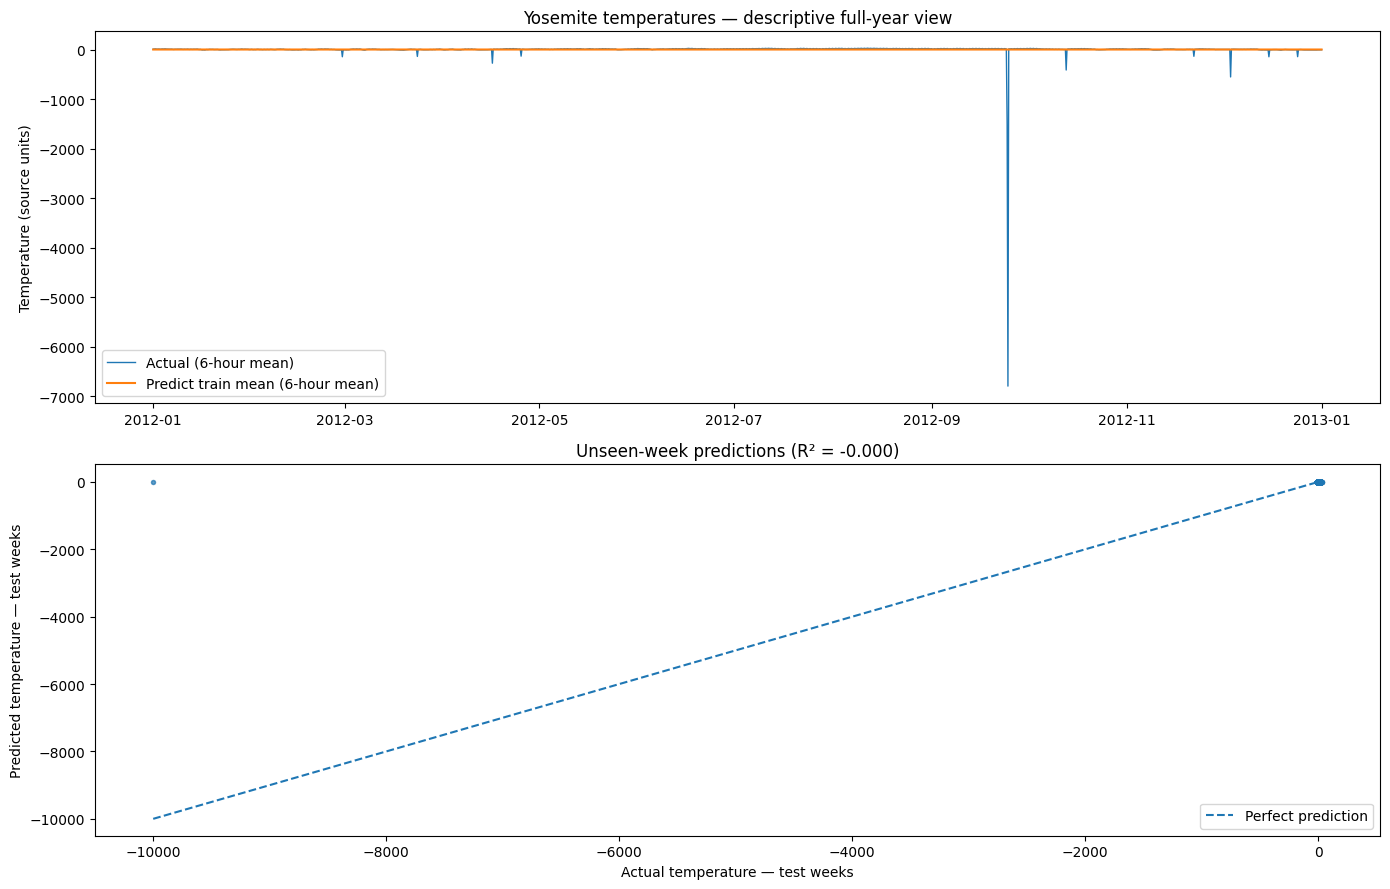

In [32]:

# Predicting the full time series for visual interpretation
all_times = pd.DatetimeIndex(yosemite["timestamp"])
all_features = make_features(all_times, winning_kind)
all_predictions = winning_model.predict(all_features)

# Building a time-series comparison
view = yosemite[["timestamp", "temperature"]].copy()
view["prediction"] = all_predictions

# Averaging over six-hour intervals for readability
view = view.set_index("timestamp").resample("6h").mean().dropna()

# Preparing held-out test predictions
test_view = pd.DataFrame({
    "Actual": y_test,
    "Predicted": test_predictions})

# Creating two comparison plots
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Plotting the full time series
axes[0].plot(view.index, view["temperature"], label="Actual (6-hour mean)", linewidth=1)
axes[0].plot(view.index, view["prediction"], label=f"{winner['Model']} (6-hour mean)", linewidth=1.5)

axes[0].set_title("Yosemite temperatures — descriptive full-year view")
axes[0].set_ylabel("Temperature (source units)")
axes[0].legend()

# Plotting actual versus predicted test values
axes[1].scatter(test_view["Actual"], test_view["Predicted"], alpha=0.15, s=8)

low = min(test_view.min())
high = max(test_view.max())

axes[1].plot([low, high], [low, high], linestyle="--", label="Perfect prediction")

axes[1].set_xlabel("Actual temperature — test weeks")
axes[1].set_ylabel("Predicted temperature — test weeks")
axes[1].set_title(f"Unseen-week predictions (R² = {final_r2:.3f})")
axes[1].legend()

plt.tight_layout()
plt.show()



## Yosemite Question H — Did the New Techniques Improve R²?

### Question

Did Fourier features, Gaussian RBFs, and Ridge or Lasso regularization improve the Yosemite temperature prediction model?

### My Evaluation

I compare the models using validation R² and MAE. The model with the highest validation R² is selected for the final test evaluation.

This comparison helps me determine whether the improvement comes from the feature representation, regularization, or their combination.

### What I Expect to Learn

**If Fourier performs better:** Repeating daily and seasonal patterns may be represented more effectively by sine and cosine functions.

**If Gaussian RBF performs better:** Smooth local patterns around different times of day and year may be especially useful for temperature prediction.

**If Ridge performs better:** Keeping many small feature contributions may be more useful than removing features.

**If Lasso performs better:** Some of the generated features may be unnecessary, and selecting a smaller set may improve generalization.

**If the hybrid model performs better:** Combining periodic and locally focused features may provide additional predictive information.

### Limitations

Temperature depends on more than time and season. Clouds, storms, wind, and other weather conditions can create changes that cannot be predicted using timestamps alone.

Therefore, even a flexible nonlinear model may fail to explain all temperature variation.

I will compare the test R² with the earlier classroom reference of approximately 0.62, but only cautiously because the evaluation splits may differ.


In [33]:

# Retrieving the linear baseline validation performance
baseline_row = best_by_model.loc[best_by_model["Model"] == "Linear time baseline"].iloc[0]

# Summarizing the completed Yosemite experiment
print("Session Interpretation")
print()

print(f"I tested Fourier and Gaussian RBF representations with Ridge and Lasso regularization.")
print(f"The strongest model on validation weeks was {winner['Model']}.")
print(f"Its validation R² was {winner['Validation R2']:.3f}.")
print(f"On untouched test weeks, it achieved R² = {final_r2:.3f}.")
print(f"The linear-time baseline achieved validation R² = {baseline_row['Validation R2']:.3f}.")
print()

print("These results show how feature representation and regularization strength influence predictive performance.")
print("The classroom R² of approximately 0.62 is not directly comparable without matching evaluation splits.")


Session Interpretation

I tested Fourier and Gaussian RBF representations with Ridge and Lasso regularization.
The strongest model on validation weeks was Predict train mean.
Its validation R² was -0.016.
On untouched test weeks, it achieved R² = -0.000.
The linear-time baseline achieved validation R² = -0.035.

These results show how feature representation and regularization strength influence predictive performance.
The classroom R² of approximately 0.62 is not directly comparable without matching evaluation splits.



# Final Reflection — Connecting the PCW and Yosemite Modeling

## What I Learned About Regularization

The original PCW helped me understand how regularization modifies the optimization problem.

Instead of only minimizing prediction error, the model also considers coefficient size. This changes the loss function and can shift its minimum toward smaller coefficients.

The repeated sampling experiment showed me how to quantify parameter stability through variance.

## What I Learned About High-Dimensional Modeling

The Yosemite extension demonstrated how basis functions can transform simple time inputs into many features.

Fourier features capture repeating patterns, while Gaussian RBFs represent smooth nonlinear relationships.

These transformations make a linear model more flexible, but they also create more coefficients to estimate.

Regularization becomes useful because it helps control this additional flexibility.

## Ridge vs. Lasso

Ridge uses a squared L2 penalty and generally keeps all coefficients while shrinking them.

Lasso uses an L1 penalty and can set some coefficients exactly to zero, performing feature selection.

I compared both methods to see whether retaining many features or selecting fewer features was more effective for Yosemite temperature prediction.

## My Overall Interpretation

A more flexible model does not automatically produce better predictions.

Good performance depends on choosing appropriate features, selecting regularization strength carefully, and evaluating the model on unseen observations.

The central lesson from this session is that optimization, feature engineering, and generalization are closely connected.

## References

- Starmer, J. (2018). Regularization Part 1: Ridge (L2) Regression.
- Starmer, J. (2018). Regularization Part 2: Lasso (L1) Regression.
- Starmer, J. (2020). Ridge vs. Lasso Regression, Visualized.
- Parr, T. (2020). A Visual Explanation for Regularization of Linear Models.
- Wilber, J., & Werness, B. (2021). The Bias Variance Tradeoff.
- CS156 Session 15: Basis Functions 2 — Ridge and Lasso.
- Yosemite temperature dataset: Prof-Watson GitHub Gist.

**Reproducibility note:** The Yosemite results must be generated by running the notebook on the real dataset. The R² values are not known in advance.
